In [ ]:
import warnings
warnings.filterwarnings('ignore')

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

In [ ]:
df = pd.read_excel('/content/drive/MyDrive/소방안전/모델/train (1).xlsx')
df

,GRID_ID,month,day,hol,pop,평균 풍속(m/s),b_point,a_point,n_point,cat
0,378509,1,1,1,5.22,1.8,37,0,0,N
1,378509,1,2,1,0.00,1.9,37,0,0,N
2,378509,1,3,1,0.00,1.2,37,0,0,N
3,378509,1,4,0,0.00,1.3,37,0,0,N
4,378509,1,5,0,0.00,1.8,37,0,0,N
...,...,...,...,...,...,...,...,...,...,...
167670,418518,12,26,1,0.00,0.8,17,0,0,N
167671,418518,12,27,0,0.00,0.8,17,0,0,N
167672,418518,12,28,0,0.00,0.5,17,0,0,N
167673,418518,12,29,0,0.00,0.8,17,0,0,N


In [ ]:
df = df[df['month']!=12]
df

,GRID_ID,month,day,hol,pop,평균 풍속(m/s),b_point,a_point,n_point,cat
0,378509,1,1,1,5.22,1.8,37,0,0,N
1,378509,1,2,1,0.00,1.9,37,0,0,N
2,378509,1,3,1,0.00,1.2,37,0,0,N
3,378509,1,4,0,0.00,1.3,37,0,0,N
4,378509,1,5,0,0.00,1.8,37,0,0,N
...,...,...,...,...,...,...,...,...,...,...
167640,418518,11,25,0,0.00,1.6,17,0,0,N
167641,418518,11,26,0,0.00,1.6,17,0,0,N
167642,418518,11,27,1,0.00,1.1,17,0,0,N
167643,418518,11,28,1,0.00,1.3,17,0,0,N


In [ ]:
# 행별 고유 인덱스 부여
df2 = df.copy()
df2['index'] = df2[['GRID_ID', 'month', 'day']].apply(lambda row: ','.join(row.values.astype(str)), axis=1)
df2.set_index('index', inplace=True)
df2 = df2.drop(columns=['GRID_ID'])

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
cols = list(df2.columns)
cols.remove('cat')
# cols
for col in cols:
    df2[col] = scaler.fit_transform(df2[[col]])
df2

,month,day,hol,pop,평균 풍속(m/s),b_point,a_point,n_point,cat
index,,,,,,,,,
"378509,1,1",-1.590986,-1.671225,1.482572,-0.297122,-0.269646,-0.170462,-0.181883,-0.483462,N
"378509,1,2",-1.590986,-1.553492,1.482572,-0.297434,-0.202665,-0.170462,-0.181883,-0.483462,N
"378509,1,3",-1.590986,-1.435759,1.482572,-0.297434,-0.671531,-0.170462,-0.181883,-0.483462,N
"378509,1,4",-1.590986,-1.318026,-0.674503,-0.297434,-0.604550,-0.170462,-0.181883,-0.483462,N
"378509,1,5",-1.590986,-1.200293,-0.674503,-0.297434,-0.269646,-0.170462,-0.181883,-0.483462,N
...,...,...,...,...,...,...,...,...,...
"418518,11,25",1.579208,1.154366,-0.674503,-0.297434,-0.403608,-0.279454,-0.181883,-0.483462,N
"418518,11,26",1.579208,1.272099,-0.674503,-0.297434,-0.403608,-0.279454,-0.181883,-0.483462,N
"418518,11,27",1.579208,1.389832,1.482572,-0.297434,-0.738512,-0.279454,-0.181883,-0.483462,N


In [ ]:
x_train = df2.iloc[:, :-1]
y_train = df2.iloc[:, -1]

In [ ]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()
encoder= encoder.fit(y_train) 
y_train = encoder.transform(y_train) 

In [ ]:
# 데이터 분리
from sklearn.model_selection import train_test_split
X_train, X_val, y_train, y_val = train_test_split(x_train, y_train, test_size=0.3, random_state=0)

In [ ]:
import numpy as np

def CreateBalancedSampleWeights(y_train, largest_class_weight_coef):
    classes = np.unique(y_train, axis = 0)
    classes.sort()
    class_samples = np.bincount(y_train)
    total_samples = class_samples.sum()
    n_classes = len(class_samples)
    weights = total_samples / (n_classes * class_samples * 1.0)
    class_weight_dict = {key : value for (key, value) in zip(classes, weights)}
    class_weight_dict[classes[1]] = class_weight_dict[classes[1]] * largest_class_weight_coef
    sample_weights = [class_weight_dict[y] for y in y_train]

    return sample_weights

In [ ]:
largest_class_weight_coef = max(df2['cat'].value_counts().values)/df2.shape[0]
weights = CreateBalancedSampleWeights(y_train, largest_class_weight_coef)

In [ ]:
from xgboost import XGBClassifier
model = XGBClassifier(n_estimators=200, max_depth=7, sample_weight=weights, random_state=0)
model.fit(X_train, y_train)
pred = model.predict(X_val)

In [ ]:
from sklearn.metrics import roc_auc_score, accuracy_score, precision_score, recall_score, f1_score
print('정확도: {0:.4f}'.format(accuracy_score(y_val, pred)))

정확도: 0.9832


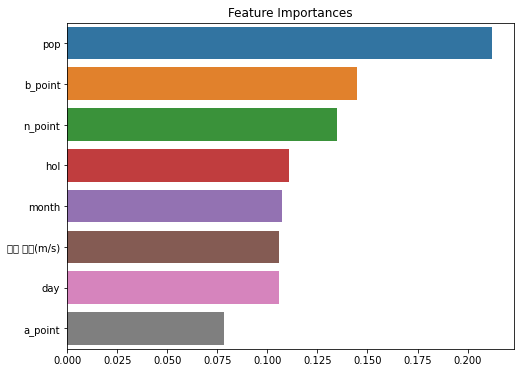

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.font_manager as fm
plt.rc('font', family='NanumGothic')
%matplotlib inline

ftr_importances_values = model.feature_importances_
ftr_importances = pd.Series(ftr_importances_values, index=X_train.columns)
ftr_importances = ftr_importances.sort_values(ascending=False)

plt.figure(figsize=(8, 6))
plt.title('Feature Importances')
sns.barplot(x=ftr_importances, y=ftr_importances.index)

In [ ]:
df2.reset_index(drop=False, inplace=True)

In [ ]:
X_val.reset_index(drop=False, inplace=True)

In [ ]:
df_ch = pd.merge(df2, X_val, how='inner')
df_ch

,index,month,day,hol,pop,평균 풍속(m/s),b_point,a_point,n_point,cat
0,"378509,1,1",-1.590986,-1.671225,1.482572,-0.297122,-0.269646,-0.170462,-0.181883,-0.483462,N
1,"378509,1,7",-1.590986,-0.964827,-0.674503,-0.297434,0.601106,-0.170462,-0.181883,-0.483462,N
2,"378509,1,13",-1.590986,-0.258429,-0.674503,-0.297434,0.065259,-0.170462,-0.181883,-0.483462,N
3,"378509,1,15",-1.590986,-0.022963,-0.674503,-0.297434,0.601106,-0.170462,-0.181883,-0.483462,N
4,"378509,1,18",-1.590986,0.330235,-0.674503,-0.297434,-0.068703,-0.170462,-0.181883,-0.483462,N
...,...,...,...,...,...,...,...,...,...,...
46023,"418518,11,10",1.579208,-0.611628,-0.674503,-0.297434,-0.202665,-0.279454,-0.181883,-0.483462,N
46024,"418518,11,11",1.579208,-0.493895,-0.674503,-0.297434,-0.001722,-0.279454,-0.181883,-0.483462,N
46025,"418518,11,13",1.579208,-0.258429,1.482572,-0.297434,-0.604550,-0.279454,-0.181883,-0.483462,N
46026,"418518,11,21",1.579208,0.683434,1.482572,-0.297434,-0.805493,-0.279454,-0.181883,-0.483462,N


In [ ]:
pred = pd.DataFrame(pred, columns=['pred'])

In [ ]:
ch = pd.concat([X_val, pred], axis=1)

In [ ]:
for i, label in enumerate(encoder.classes_):
  print(i, "->", label) 

0 -> ACDNT_INJ_OCRN_CNT
1 -> ANML_INSCT_ACDNT_OCRN_CNT
2 -> ASPHYXIA_OCRN_CNT
3 -> BCYC_ACDNT_OCRN_CNT
4 -> BLTRM_OCRN_CNT
5 -> BURN_OCRN_CNT
6 -> DRKNSTAT_OCRN_CNT
7 -> DRV_ACDNT_OCRN_CNT
8 -> DRWNG_OCRN_CNT
9 -> ELTRC_ACDNT_OCRN_CNT
10 -> ETC_OCRN_CNT
11 -> EXCL_DISEASE_OCRN_CNT
12 -> FALLING_OCRN_CNT
13 -> FLAME_OCRN_CNT
14 -> FLPS_ACDNT_OCRN_CNT
15 -> HGTPOJ_ACDNT_OCRN_CNT
16 -> HRFAF_OCRN_CNT
17 -> LACRTWND_OCRN_CNT
18 -> MCHN_ACDNT_OCRN_CNT
19 -> MTRCYC_ACDNT_OCRN_CNT
20 -> N
21 -> PDST_ACDNT_OCRN_CNT
22 -> POSNG_OCRN_CNT
23 -> PRGNTW_ACDNT_OCRN_CNT
24 -> THML_DAMG_OCRN_CNT
25 -> UNKNWN_OCRN_CNT
26 -> VHC_ACDNT_OCRN_CNT


In [ ]:
ch.to_excel("check_02.xlsx", index=False)

In [ ]:
df_ch.to_excel("df_check_02.xlsx", index=False)